# Robustez: perturbación adversarial controlada

## Pregunta y decisión
¿Un indicador de cambio o una perturbación controlada ayuda a decidir qué revisar en el monitoreo de un modelo? La unidad de análisis es una observación de diagnóstico incluida en un conjunto público; el ejemplo sirve para estudiar métodos de validación y no para uso clínico ni para validar un sistema institucional.

## Datos y fuente
El [conjunto Breast Cancer Wisconsin Diagnostic](https://doi.org/10.24432/C5DW2B) contiene 569 observaciones y 30 variables de imágenes; UCI lo distribuye bajo CC BY 4.0 (Wolberg, Mangasarian, Street y Street, 1993). Se usa la copia incluida en [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html). Variable objetivo: maligno = 1. No hay marcas de tiempo ni una validación externa.

**Entorno:** Python, numpy, pandas, matplotlib, scikit-learn, nbformat y Jupyter. Ejecución desde cualquier directorio; no requiere red. Se muestra la versión y huella del dataset transformado para rastrear posibles diferencias de entorno.

**Resultado de esta ejecución:** en 200 observaciones de prueba, epsilon 0,10 cambia 10 decisiones; con epsilon 0,25 cambian 52. Las perturbaciones usan las etiquetas y el gradiente del modelo, bajo supuestos descritos abajo.

## 1. Preparación y separación de datos

In [1]:
from pathlib import Path
import hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix
plt.rcParams.update({'figure.figsize':(8,4.5),'axes.grid':True})
print('scikit-learn:',sklearn.__version__)

scikit-learn: 1.5.2


In [2]:
dataset=load_breast_cancer(as_frame=True)
X=dataset.data.copy(); y=(dataset.target==0).astype(int)  # 1 = maligno
assert len(X)==569 and not X.isna().any().any() and set(y.unique())=={0,1}
print('Observaciones:',len(X),'| Variables:',X.shape[1],'| Positivos (maligno):',int(y.sum()))
print('SHA-256 CSV generado desde matriz y etiqueta:',hashlib.sha256(pd.concat([X,y.rename('maligno')],axis=1).to_csv(index=False).encode()).hexdigest())
X.iloc[:3,:5]

Observaciones: 569 | Variables: 30 | Positivos (maligno): 212
SHA-256 CSV generado desde matriz y etiqueta: e00eccff3e5ac5f9a2d0c1835d45f6a7bcee1b278d890f4c57c531ba45955516


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.8,1001.0,0.11840
1,20.57,17.77,132.9,1326.0,0.08474
2,19.69,21.25,130.0,1203.0,0.10960


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.35,random_state=42,stratify=y)
scaler=StandardScaler().fit(X_train)
z_train=scaler.transform(X_train); z_test=scaler.transform(X_test)
model=LogisticRegression(max_iter=3000,random_state=42).fit(z_train,y_train)
assert set(X_train.index).isdisjoint(X_test.index)
print('Entrenamiento:',len(X_train),'| Prueba:',len(X_test),'| prevalencia prueba:',round(y_test.mean(),3))

Entrenamiento: 369 | Prueba: 200 | prevalencia prueba: 0.375


## 2. Referencia: regresión logística
El escalado se ajusta solo con entrenamiento. El umbral 0,5 es ilustrativo; las métricas no sustituyen calibración, validación externa ni selección de umbral basada en costes. La evaluación se hace sobre las mismas observaciones de prueba en ambas variantes.

In [4]:
def metrics(y_true,score):
    prediction=(score>=0.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,prediction,labels=[0,1]).ravel()
    return {'n':len(y_true),'prevalencia':np.mean(y_true),'AUC':roc_auc_score(y_true,score) if len(np.unique(y_true))==2 else np.nan,'Brier':brier_score_loss(y_true,score),'sensibilidad':tp/(tp+fn) if tp+fn else np.nan,'falsos_negativos':int(fn),'falsos_positivos':int(fp)}
p_base=model.predict_proba(z_test)[:,1]
pd.Series(metrics(y_test,p_base)).round(4)

n                   200.0000
prevalencia           0.3750
AUC                   0.9972
Brier                 0.0231
sensibilidad          0.9067
falsos_negativos      7.0000
falsos_positivos      0.0000
dtype: float64

## 3. Perturbación de evasión sobre variables estandarizadas
Con pesos de la regresión logística y etiquetas conocidas, modificamos simultáneamente cada variable estandarizada en la dirección del gradiente que aumenta la pérdida logística. El escenario concede al atacante acceso al modelo y etiqueta, y usa $\epsilon$ en desviaciones estándar del entrenamiento.

Las perturbaciones son **construidas**, pueden producir combinaciones físicamente imposibles y mantener la etiqueta original podría ser inválido tras el cambio. Son un límite de sensibilidad bajo supuestos fuertes, no evidencia de un ataque real. [NIST AI 100-2e2025](https://doi.org/10.6028/NIST.AI.100-2e2025) describe la taxonomía de ataques de evasión; no certifica este experimento.

In [5]:
coef=model.coef_[0]
# Gradiente de log-loss para etiqueta binaria en coordenadas estandarizadas.
gradient=(p_base-y_test.to_numpy())[:,None]*coef[None,:]
assert gradient.shape==z_test.shape
rows=[]
for epsilon in [0.,0.05,0.10,0.25,0.50]:
    z_stress=z_test+epsilon*np.sign(gradient)
    score=model.predict_proba(z_stress)[:,1]
    result=metrics(y_test,score);result['epsilon']=epsilon;result['cambios_de_decision']=int(((score>=.5)!=(p_base>=.5)).sum());rows.append(result)
results=pd.DataFrame(rows).set_index('epsilon')
assert results.loc[0.,'cambios_de_decision']==0
results.round(4)

,n,prevalencia,AUC,Brier,sensibilidad,falsos_negativos,falsos_positivos,cambios_de_decision
epsilon,,,,,,,,
0.00,200,0.375,0.9972,0.0231,0.9067,7,0,0
0.05,200,0.375,0.9886,0.0407,0.8800,9,1,3
0.10,200,0.375,0.9647,0.0674,0.8267,13,4,10
0.25,200,0.375,0.7603,0.2226,0.6400,27,32,52
0.50,200,0.375,0.3201,0.6202,0.4267,43,104,140


## 4. Curvas de sensibilidad y coste de errores

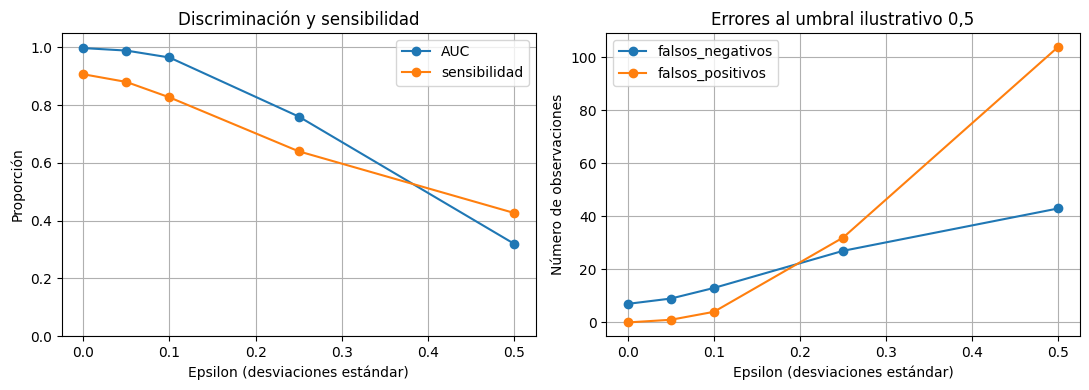

In [6]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
results[['AUC','sensibilidad']].plot(marker='o',ax=axs[0]);axs[0].set(title='Discriminación y sensibilidad',xlabel='Epsilon (desviaciones estándar)',ylabel='Proporción',ylim=(0,1.05));axs[0].legend()
results[['falsos_negativos','falsos_positivos']].plot(marker='o',ax=axs[1]);axs[1].set(title='Errores al umbral ilustrativo 0,5',xlabel='Epsilon (desviaciones estándar)',ylabel='Número de observaciones');plt.tight_layout();plt.show()

## 5. Comparación con ruido no dirigido
Para las mismas intensidades se aplica una sola matriz de signos aleatorios con semilla fija y la misma cota por variable. La comparación contrasta dos escenarios sobre las mismas observaciones: no es una distribución de ataques ni una estimación de frecuencia en producción. La perturbación sigue sin validar plausibilidad física.

In [7]:
rng=np.random.default_rng(42)
noise=rng.choice([-1.,1.],size=z_test.shape)
comparison=[]
for epsilon in [0.05,0.10,0.25,0.50]:
    for scenario,delta in [('gradiente',np.sign(gradient)),('ruido aleatorio',noise)]:
        scores=model.predict_proba(z_test+epsilon*delta)[:,1]
        comparison.append({'epsilon':epsilon,'escenario':scenario,'AUC':roc_auc_score(y_test,scores),'Brier':brier_score_loss(y_test,scores),'decisiones_cambiadas':int(((scores>=.5)!=(p_base>=.5)).sum())})
pd.DataFrame(comparison).round(4)

,epsilon,escenario,AUC,Brier,decisiones_cambiadas
0,0.05,gradiente,0.9886,0.0407,3
1,0.05,ruido aleatorio,0.9968,0.0237,1
2,0.10,gradiente,0.9647,0.0674,10
3,0.10,ruido aleatorio,0.9965,0.0245,2
4,0.25,gradiente,0.7603,0.2226,52
5,0.25,ruido aleatorio,0.9938,0.0279,3
6,0.50,gradiente,0.3201,0.6202,140
7,0.50,ruido aleatorio,0.9858,0.0377,7


## 6. Limitaciones y decisión
Las filas comparadas son las mismas, por lo que las diferencias describen este ensayo controlado. El acceso a etiquetas y pesos supone un atacante fuerte; tampoco se impusieron restricciones físicas ni se validó si las etiquetas sobreviven a cada perturbación. Antes de aceptar un modelo se necesitan datos externos, riesgos y capacidades del adversario definidos, restricciones de factibilidad y evaluación independiente. Esta demostración no orienta decisiones clínicas.